In [288]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import squarify
import seaborn as sns

In [7]:
# -- Pandas display options (from marketing notebook) --
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams['font.size'] = 12
path_dataClean =  "dataCleaned/"

In [15]:
# Khách hàng và Doanh thu
orders =  pd.read_csv(path_dataClean + "cleaned_orders.csv")
payments =  pd.read_csv(path_dataClean + "cleaned_payments.csv")
customers =  pd.read_csv(path_dataClean + "customers_cleaned.csv")
geo =  pd.read_csv(path_dataClean + "geography_cleaned.csv")
sales     = pd.read_csv(path_dataClean + 'sale_cleaned.csv')


print("orders   :", orders.shape)
print("payments :", payments.shape)
print("customers:", customers.shape)
print("geo      :", geo.shape)
print("sales    :", sales.shape)


orders   : (646945, 8)
payments : (646945, 4)
customers: (121930, 7)
geo      : (39948, 5)
sales    : (3833, 3)


### Mục tiêu

1. Tìm số lượng đơn hàng và doanh thu biến động như nào qua các mốc thời gian. Khi nào thì đạt đỉnh
2. Nhóm khách hàng đóng góp chính vào trong khối lượng mà nhóm khách hàng đó đã chi cho doanh nghiệp(Phân theo độ tuổi, giới tính và khu vực)
3. Doanh thu theo thời gian tìm ra thông tin về tháng có Doanh thu cao nhất và thấp nhất.
4. Hình thức mang lại rủi ro cao nhất, tỷ lệ hoàn hàng và hủy đơn ở đâu
5. Nhóm khách hàng nào có AOV cao nhất và kênh truyền thông nào mang khách hàng đến doanh nghiệp
6. Tìm kiếm nhóm khách hàng mang lại doanh thu cao nhất. Nhóm khách hàng có nguy cơ rời bỏ cao nhất

In [24]:
df1 = orders[orders['order_status'] == 'delivered'].copy()
df1["order_date"] = pd.to_datetime(df1["order_date"])
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 516716 entries, 0 to 646944
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   order_id        516716 non-null  int64         
 1   order_date      516716 non-null  datetime64[ns]
 2   customer_id     516716 non-null  int64         
 3   zip             516716 non-null  int64         
 4   order_status    516716 non-null  object        
 5   payment_method  516716 non-null  object        
 6   device_type     516716 non-null  object        
 7   order_source    516716 non-null  object        
dtypes: datetime64[ns](1), int64(3), object(4)
memory usage: 35.5+ MB


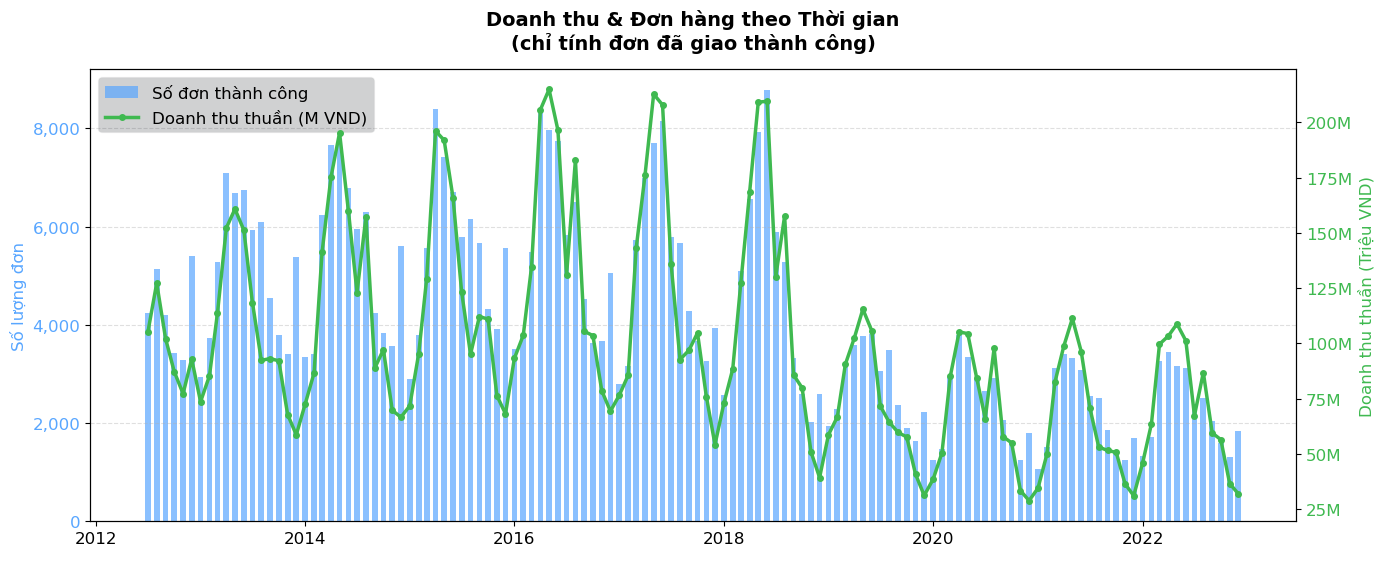

In [50]:
# ── Chart 1: Revenue & Orders over Time (delivered only) ──
df1 = orders[orders['order_status'] == 'delivered'].copy()
df1["order_date"] = pd.to_datetime(df1["order_date"])
df1 = df1.merge(payments[['order_id','payment_value']], on='order_id', how='left')
df1['month'] = df1['order_date'].dt.to_period('M')

monthly = df1.groupby('month').agg(
    num_orders    = ('order_id',      'count'),
    net_revenue   = ('payment_value', 'sum')
).reset_index()
monthly['month_dt'] = monthly['month'].dt.to_timestamp()

fig, ax1 = plt.subplots(figsize=(14, 6))

# Bar – order count
bars = ax1.bar(monthly['month_dt'], monthly['num_orders'],
               width=20, color='#58A6FF', alpha=0.7, label='Số đơn thành công')
ax1.set_xlabel('Thời gian (Tháng/Năm)', fontsize=12, labelpad=8, color = "white")
ax1.set_ylabel('Số lượng đơn', color='#58A6FF', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#58A6FF')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

# Line – revenue
ax2 = ax1.twinx()
ax2.set_facecolor('#161B22')
ax2.plot(monthly['month_dt'], monthly['net_revenue'] / 1e6,
         color='#3FB950', linewidth=2.5, marker='o', markersize=4, label='Doanh thu thuần (M VND)')
ax2.set_ylabel('Doanh thu thuần (Triệu VND)', color='#3FB950', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#3FB950')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}M'))

ax1.grid(axis='y', linestyle='--', alpha=0.4)
plt.title('Doanh thu & Đơn hàng theo Thời gian\n(chỉ tính đơn đã giao thành công)',
          fontsize=14, fontweight='bold', pad=14)

h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1+h2, l1+l2, loc='upper left', framealpha=0.2, facecolor='#161B22')

plt.tight_layout()
plt.show()


**Đánh giá**

- **Tăng trưởng dài hạn:** Hoạt động kinh doanh ghi nhận sự tăng trưởng liên tục về mặt quy mô kể từ khi bắt đầu vào **tháng 07/2012**.
- **Đỉnh cao giao dịch:** Lượng đơn hàng giao thành công (Delivered) và Doanh thu thực nhận (Net Revenue) duy trì đà tăng ấn tượng và tạo đỉnh vào **tháng 05/2016** với mức doanh thu đạt **~215 tỷ VND** / tháng.
- **Tính mùa vụ:** Có thể quan sát thấy những đợt tăng vọt chu kỳ vào các dịp cuối năm, cho thấy nền tảng đang tận dụng tốt các đợt bùng nổ nhu cầu mua sắm.
- **Kết luận:** Nền tảng đã mở rộng thị phần rất tốt và thu hút được lượng lớn giao dịch qua các năm. Tuy nhiên, đà tăng trưởng có dấu hiệu đi ngang và chững lại ở giai đoạn sau, đòi hỏi những chiến lược tối ưu thay vì chỉ mở rộng ròng.


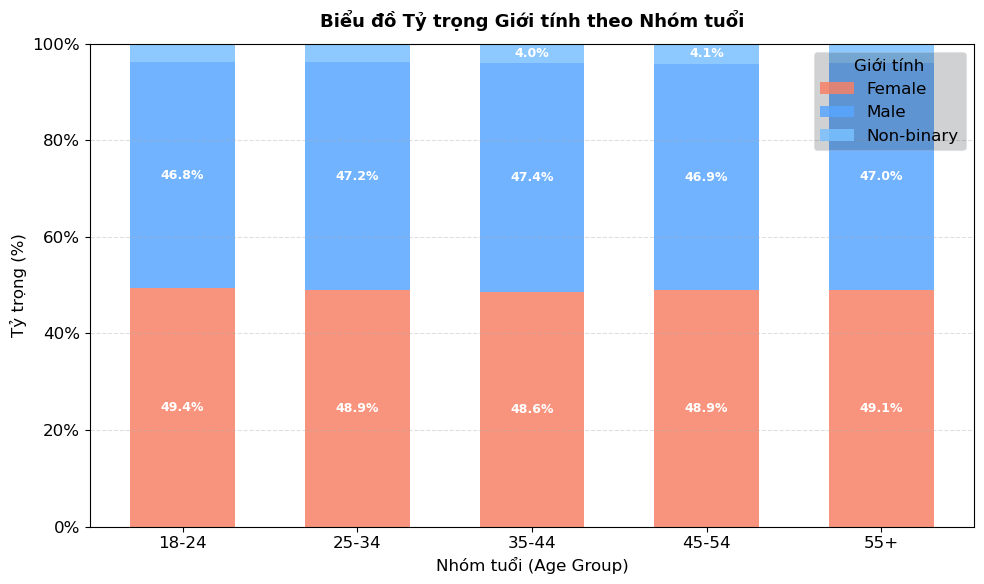

gender,Female,Male,Non-binary
age_group,,,
18-24,49.3515,46.7692,3.8793
25-34,48.9379,47.2098,3.8523
35-44,48.5746,47.3966,4.0288
45-54,48.9082,46.9489,4.1429
55+,49.1046,46.9867,3.9087


In [145]:
# ── Chart 2: 100% Stacked Bar – Age Group × Gender ──
AGE_ORDER = ['18-24','25-34','35-44','45-54','55+']

df2 = customers.copy()
df2['age_group'] = pd.Categorical(df2['age_group'], categories=AGE_ORDER, ordered=True)
pivot = df2.groupby(['age_group','gender'])['customer_id'].count().unstack(fill_value=0)
pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 6))

colors_gender = {'Male': '#58A6FF', 'Female': '#F78166', 'Other': '#D2A8FF'}
bottom = np.zeros(len(pivot_pct))

for gender in pivot_pct.columns:
    color = colors_gender.get(gender, '#79C0FF')
    vals  = pivot_pct[gender].values
    bars  = ax.bar(pivot_pct.index.astype(str), vals, bottom=bottom,
                   label=gender, color=color, alpha=0.85, width=0.6)
    # Label inside bar if wide enough
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 4:
            ax.text(i, b + v/2, f'{v:.1f}%', ha='center', va='center',
                    fontsize=9, color='white', fontweight='bold')
    bottom += vals

ax.set_ylim(0, 100)
ax.set_ylabel('Tỷ trọng (%)', fontsize=12)
ax.set_xlabel('Nhóm tuổi (Age Group)', fontsize=12)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x)}%'))
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend(title='Giới tính', loc='upper right', framealpha=0.2, facecolor='#161B22')
plt.title('Biểu đồ Tỷ trọng Giới tính theo Nhóm tuổi',
          fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()
display(pivot_pct)

In [167]:
df2["age_group"].value_counts(normalize=True).reset_index()

,age_group,proportion
0,25-34,0.2981
1,35-44,0.2618
2,45-54,0.1900
3,18-24,0.1397
4,55+,0.1104


**Đánh giá**

- **Độ phủ rộng rãi:** Cấu trúc khách hàng khá đa dạng và cân bằng. Tỷ lệ giới tính **Nữ (48.9%)** và **Nam (47.1%)** phân bổ tương đối đồng đều ở mọi nhóm tuổi, cho thấy tệp sản phẩm phục vụ được nhu cầu đại chúng mà không bị lệch hẳn về một giới tính nào.
- **Lực lượng chủ chốt:** Nhóm tuổi **25-34** là "xương sống" của nền tảng, chiếm tỷ trọng cao nhất với **29.8%** tổng quy mô khách hàng. Kế đó là nhóm 35-44 và 18-24.
- **Kết luận:** Số lượng khách hàng ở nhóm **25-34** đang là nhóm có số lượng đông đảo nhất, những người có thu nhập ổn định và quen thuộc với thương mại điện tử. Đây là nền tảng vững chắc để xây dựng các chiến dịch Marketing cá nhân hóa và chương trình Loyalty.


# Nháp - cus với geo

In [152]:
# dfgeo_copy = geo[["zip", "region"]].copy()
# dfcus_copy = customers.copy()
# dfregioncustomer =  pd.merge(dfcus_copy, dfgeo_copy, on='zip', how='inner')

In [154]:
# dfregioncustomer

In [156]:
# dfregioncustomer_East = dfregioncustomer[dfregioncustomer["region"] == "East"]
# dfregioncustomer_East['age_group'] = pd.Categorical(dfregioncustomer_East['age_group'], categories=AGE_ORDER, ordered=True)
# pivot = dfregioncustomer_East.groupby(['age_group','gender'])['customer_id'].count().unstack(fill_value=0)
# pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

# fig, ax = plt.subplots(figsize=(10, 6))

# colors_gender = {'Male': '#58A6FF', 'Female': '#F78166', 'Other': '#D2A8FF'}
# bottom = np.zeros(len(pivot_pct))

# for gender in pivot_pct.columns:
#     color = colors_gender.get(gender, '#79C0FF')
#     vals  = pivot_pct[gender].values
#     bars  = ax.bar(pivot_pct.index.astype(str), vals, bottom=bottom,
#                    label=gender, color=color, alpha=0.85, width=0.6)
#     # Label inside bar if wide enough
#     for i, (v, b) in enumerate(zip(vals, bottom)):
#         if v > 4:
#             ax.text(i, b + v/2, f'{v:.1f}%', ha='center', va='center',
#                     fontsize=9, color='white', fontweight='bold')
#     bottom += vals

# ax.set_ylim(0, 100)
# ax.set_ylabel('Tỷ trọng (%)', fontsize=12)
# ax.set_xlabel('Nhóm tuổi (Age Group)', fontsize=12)
# ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x)}%'))
# ax.grid(axis='y', linestyle='--', alpha=0.4)
# ax.legend(title='Giới tính', loc='upper right', framealpha=0.2, facecolor='#161B22')
# plt.title('Biểu đồ Tỷ trọng Giới tính theo Nhóm tuổi - Vùng phía đông',
#           fontsize=13, fontweight='bold', pad=12)
# plt.tight_layout()
# plt.show()
# print("Vùng phía đông có:",len(dfregioncustomer_East), "khách hàng")
# (dfregioncustomer_East["age_group"].value_counts().reset_index())

In [158]:
# dfregioncustomer_Central = dfregioncustomer[dfregioncustomer["region"] == "Central"]
# dfregioncustomer_Central['age_group'] = pd.Categorical(dfregioncustomer_Central['age_group'], categories=AGE_ORDER, ordered=True)
# pivot = dfregioncustomer_Central.groupby(['age_group','gender'])['customer_id'].count().unstack(fill_value=0)
# pivot_pct = pivot.div(pivot.sum(axis=1), axis=0) * 100

# fig, ax = plt.subplots(figsize=(10, 6))

# colors_gender = {'Male': '#58A6FF', 'Female': '#F78166', 'Other': '#D2A8FF'}
# bottom = np.zeros(len(pivot_pct))

# for gender in pivot_pct.columns:
#     color = colors_gender.get(gender, '#79C0FF')
#     vals  = pivot_pct[gender].values
#     bars  = ax.bar(pivot_pct.index.astype(str), vals, bottom=bottom,
#                    label=gender, color=color, alpha=0.85, width=0.6)
#     # Label inside bar if wide enough
#     for i, (v, b) in enumerate(zip(vals, bottom)):
#         if v > 4:
#             ax.text(i, b + v/2, f'{v:.1f}%', ha='center', va='center',
#                     fontsize=9, color='white', fontweight='bold')
#     bottom += vals

# ax.set_ylim(0, 100)
# ax.set_ylabel('Tỷ trọng (%)', fontsize=12)
# ax.set_xlabel('Nhóm tuổi (Age Group)', fontsize=12)
# ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x)}%'))
# ax.grid(axis='y', linestyle='--', alpha=0.4)
# ax.legend(title='Giới tính', loc='upper right', framealpha=0.2, facecolor='#161B22')
# plt.title('Biểu đồ Tỷ trọng Giới tính theo Nhóm tuổi - Miền trung',
#           fontsize=13, fontweight='bold', pad=12)
# plt.tight_layout()
# plt.show()
# print("Miền trung có:",len(dfregioncustomer_Central), "khách hàng")
# (dfregioncustomer_Central["age_group"].value_counts().reset_index())

# Hết nháp

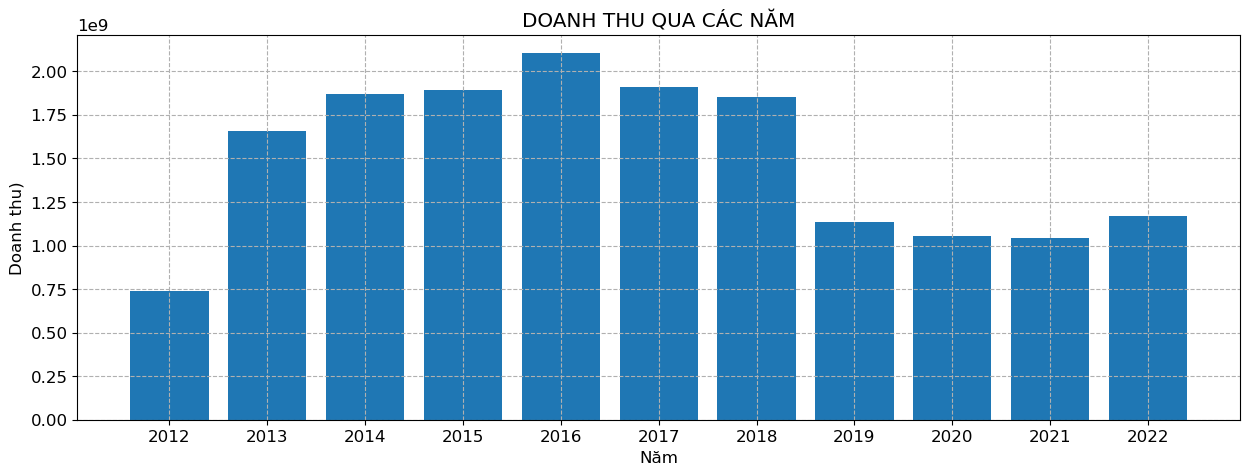

In [262]:
sales['Date'] =  pd.to_datetime(sales['Date'])
sales["year"] = sales['Date'].dt.year

revenuebyYear = sales.groupby(["year"])[["Revenue"]].sum().reset_index().sort_values(by = ['year'])
revenuebyYear[["year", "Revenue"]]
pig, ax =  plt.subplots(figsize=(15, 5))
ax.bar(
    revenuebyYear['year'],
    revenuebyYear['Revenue']
)
ax.set_ylabel('Doanh thu)')
ax.set_xlabel('Năm', fontsize=12)
ax.grid(ls = "--")
ax.set_xticks(range(min(revenuebyYear['year']),max(revenuebyYear['year'])+1))
ax.set_title("DOANH THU QUA CÁC NĂM")    
plt.show()

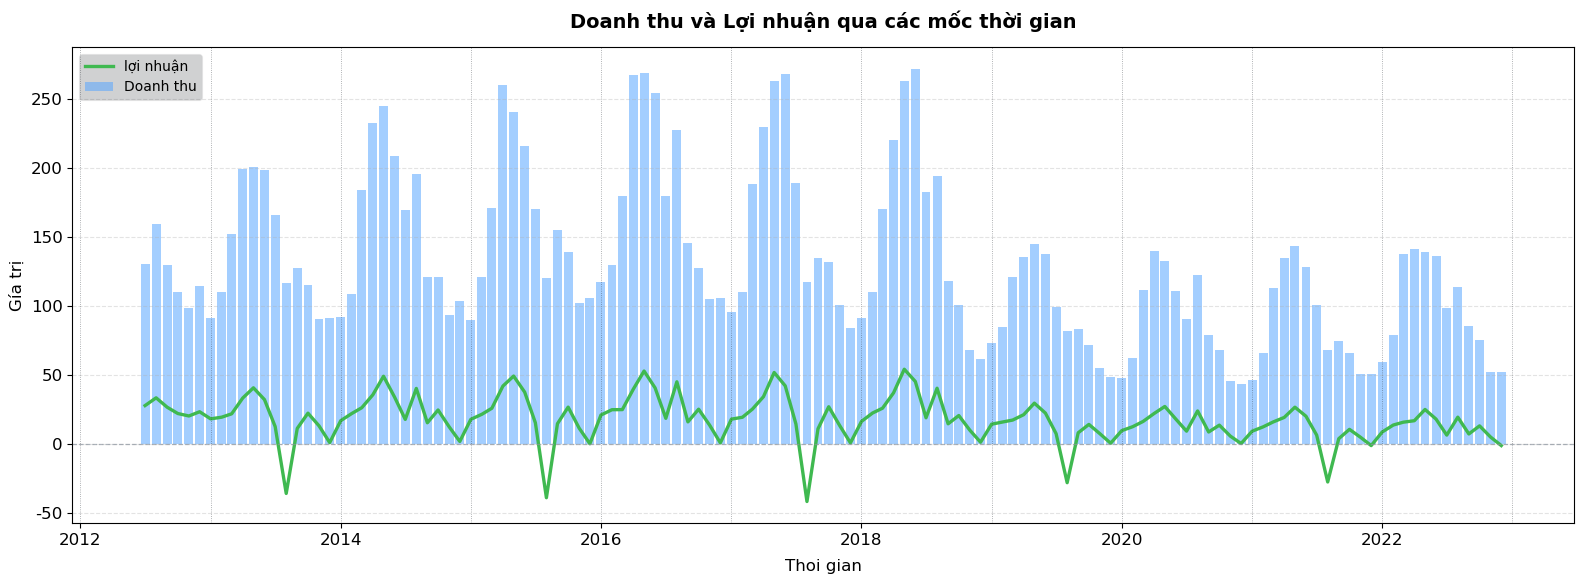

In [192]:
# ── Chart 0: Doanh thu & Loi nhuan theo Thang/Nam (sales.csv) ──
sales['Profit']    = sales['Revenue'] - sales['COGS']
sales['YearMonth'] = sales['Date'].dt.to_period('M')

monthly_s = sales.groupby('YearMonth').agg(
    Revenue = ('Revenue', 'sum'),
    Profit  = ('Profit',  'sum')
).reset_index()
monthly_s['month_dt'] = monthly_s['YearMonth'].dt.to_timestamp()

fig, ax1 = plt.subplots(figsize=(16, 6))

# Revenue bars
ax1.bar(monthly_s['month_dt'], monthly_s['Revenue'] / 1e6,
        width=25, color='#58A6FF', alpha=0.55, label='Doanh thu')

# Profit line
ax1.plot(monthly_s['month_dt'], monthly_s['Profit'] / 1e6,
         color='#3FB950', linewidth=2.4, marker='', label='lợi nhuận')

# Zero baseline
ax1.axhline(y=0, color='#8B949E', linestyle='--', linewidth=0.9, alpha=0.7)

# Year grid lines
for year in range(int(monthly_s['month_dt'].dt.year.min()),
                  int(monthly_s['month_dt'].dt.year.max()) + 2):
    ax1.axvline(pd.Timestamp(f'{year}-01-01'),
                color='#30363D', linestyle=':', linewidth=0.6, alpha=0.5)

ax1.set_xlabel('Thoi gian', fontsize=12, labelpad=8)
ax1.set_ylabel('Gía trị', fontsize=12)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax1.grid(axis='y', linestyle='--', alpha=0.35)
ax1.legend(loc='upper left', framealpha=0.2, facecolor='#161B22', fontsize=10)

plt.title('Doanh thu và Lợi nhuận qua các mốc thời gian',
          fontsize=14, fontweight='bold', pad=14)

plt.tight_layout()
plt.show()


In [190]:
monthly_s[monthly_s["Profit"] < 0]

,YearMonth,Revenue,Profit,month_dt
13,2013-08,"116,271,755.9600","-35,675,935.0400",2013-08-01
37,2015-08,"119,854,986.6300","-38,771,622.4800",2015-08-01
61,2017-08,"117,297,361.7600","-41,512,111.2500",2017-08-01
85,2019-08,"81,495,589.8600","-27,900,349.0200",2019-08-01
109,2021-08,"68,280,026.8200","-27,370,889.3800",2021-08-01
113,2021-12,"50,403,908.3500","-1,043,997.0700",2021-12-01
125,2022-12,"52,454,936.2000","-1,034,737.2400",2022-12-01


**Analysis 3**

- **Xu hướng trong năm (Tính mùa vụ):** 
  - **Tháng kinh doanh tốt nhất:** Nhìn chung, **Tháng 5** là giai đoạn "hoàng kim" trong năm khi cả Doanh thu và Lợi nhuận trung bình đều đạt mức cao nhất. Đây là thời điểm vàng để đẩy mạnh các chiến dịch kích cầu.
  - **Tháng kinh doanh ảm đạm:** Ngược lại, những tháng cuối năm (đặc biệt là **Tháng 8** và rải rác các tháng mùa thu như tháng 12) thường ghi nhận mức sụt giảm nghiêm trọng. Lợi nhuận có những tháng chạm đáy (như tháng 08/2017). Doanh nghiệp dường như đang gặp khó khăn trong việc chốt sale hoặc phải chịu chi phí vận hành quá cao vào dịp cuối năm.

- **Xu hướng qua các năm (Tác động vĩ mô):** 
  - **Giai đoạn tăng trưởng (2012 - 2018):** Doanh thu có xu hướng tăng trưởng và duy trì ở mức rất cao (đạt đỉnh **~2.1 tỷ** vào năm 2016).
  - **Cú sốc COVID-19 (2019 - 2021):** Từ năm 2019, biểu đồ cho thấy một sự "gãy gập" cực kỳ rõ rệt. Doanh thu giảm chỉ còn loanh quanh **1 tỷ/năm** (giảm gần một nửa so với thời kỳ đỉnh cao). Đại dịch đã giáng một đòn mạnh vào sức mua của thị trường. Mãi đến năm 2022, biểu đồ mới bắt đầu le lói dấu hiệu phục hồi nhẹ.

- **Nghịch lý Doanh thu - Lợi nhuận:** Mặc dù đường xu hướng Doanh thu (cột màu xanh dương) có những lúc tăng trưởng tốt, nhưng Lợi nhuận (đường màu xanh lá) lại biến động vô cùng khắc nghiệt và không hề tỷ lệ thuận với doanh thu.
- **Kết luận:** Sự gia tăng quy mô (ở giai đoạn trước COVID) hoặc nỗ lực phục hồi (hậu COVID) đang đi kèm với những rủi ro quá lớn về mặt chi phí. Doanh thu có thể có, nhưng lợi nhuận thực tế lại bị "ăn mòn". Chúng ta cần ngay lập tức đi vào chẩn đoán xem "lỗ hổng" nào đang gây ra tình trạng hao hụt này (Chuyển sang Phần 2).

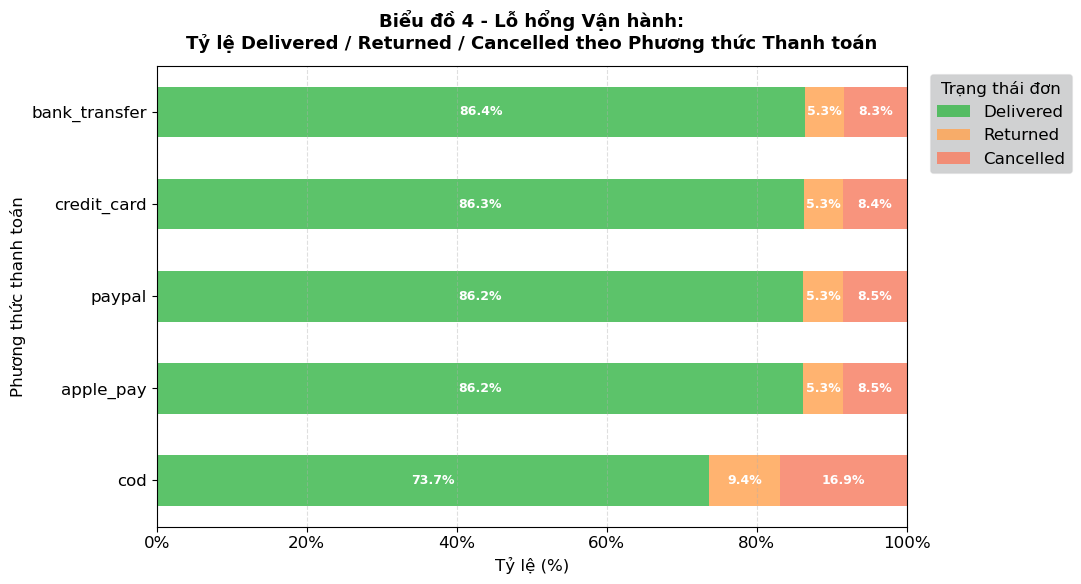

In [217]:
# ── Chart 3: 100% Stacked Bar – Payment Method × Order Status ──
STATUS_KEEP   = ['delivered','returned','cancelled']
STATUS_COLORS = {'delivered': '#3FB950', 'returned': '#FFA657', 'cancelled': '#F78166'}

df3 = orders[orders['order_status'].isin(STATUS_KEEP)].copy()
pivot3 = df3.groupby(['payment_method','order_status'])['order_id'].count().unstack(fill_value=0)
for s in STATUS_KEEP:
    if s not in pivot3.columns:
        pivot3[s] = 0
pivot3 = pivot3[STATUS_KEEP]
pivot3_pct = pivot3.div(pivot3.sum(axis=1), axis=0) * 100
pivot3_pct = pivot3_pct.sort_values('delivered', ascending=True)

fig, ax = plt.subplots(figsize=(11, 6))

bottom = np.zeros(len(pivot3_pct))
for status in STATUS_KEEP:
    vals = pivot3_pct[status].values
    ax.barh(pivot3_pct.index, vals, left=bottom,
            label=status.capitalize(), color=STATUS_COLORS[status], alpha=0.85, height=0.55)
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 3:
            ax.text(b + v/2, i, f'{v:.1f}%', ha='center', va='center',
                    fontsize=9, color='white', fontweight='bold')
    bottom += vals

ax.set_xlim(0, 100)
ax.set_xlabel('Tỷ lệ (%)', fontsize=12)
ax.set_ylabel('Phương thức thanh toán', fontsize=12)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x)}%'))
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.legend(title='Trạng thái đơn', loc='upper left', bbox_to_anchor=(1.02, 1), framealpha=0.2, facecolor='#161B22')
plt.title('Biểu đồ 4 - Lỗ hổng Vận hành:\nTỷ lệ Delivered / Returned / Cancelled theo Phương thức Thanh toán',
          fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
# plt.savefig(BASE_DIR + 'chart3_payment_status.png', dpi=150, bbox_inches='tight')
plt.show()



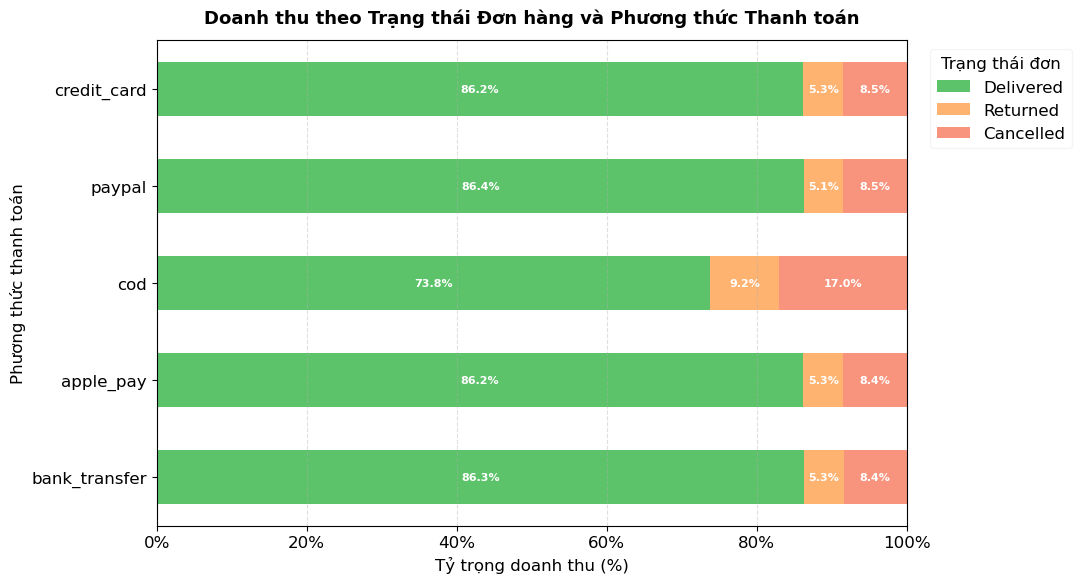

In [239]:
# ── Revenue theo Payment Method × Order Status ──

STATUS_KEEP   = ['delivered','returned','cancelled']
STATUS_COLORS = {
    'delivered': '#3FB950',
    'returned': '#FFA657',
    'cancelled': '#F78166'
}

# =========================
# Gộp orders với payments
# =========================
df_rev = orders.merge(
    payments[['order_id', 'payment_method', 'payment_value']],
    on='order_id',
    how='inner'
)

# Chỉ giữ các trạng thái cần phân tích
df_rev = df_rev[df_rev['order_status'].isin(STATUS_KEEP)].copy()

# =========================
# Tổng doanh thu theo:
# payment_method × order_status
# =========================
pivot_rev = (
    df_rev
    .groupby(['payment_method_x', 'order_status'])['payment_value']
    .sum()
    .unstack(fill_value=0)
)

# Đảm bảo đủ cột
for s in STATUS_KEEP:
    if s not in pivot_rev.columns:
        pivot_rev[s] = 0

pivot_rev = pivot_rev[STATUS_KEEP]

# =========================
# Tính tỷ trọng %
# =========================
pivot_rev_pct = pivot_rev.div(
    pivot_rev.sum(axis=1),
    axis=0
) * 100

# Sort theo doanh thu delivered
pivot_rev_pct = pivot_rev_pct.loc[
    pivot_rev['delivered'].sort_values().index
]

# =========================
# VẼ BIỂU ĐỒ
# =========================
fig, ax = plt.subplots(figsize=(11, 6))

bottom = np.zeros(len(pivot_rev_pct))

for status in STATUS_KEEP:
    vals = pivot_rev_pct[status].values

    ax.barh(
        pivot_rev_pct.index,
        vals,
        left=bottom,
        label=status.capitalize(),
        color=STATUS_COLORS[status],
        alpha=0.85,
        height=0.55
    )

    # Hiển thị % + số tiền
    for i, (v, b) in enumerate(zip(vals, bottom)):
        if v > 3:

            payment_method = pivot_rev_pct.index[i]
            revenue = pivot_rev.loc[payment_method, status]

            ax.text(
                b + v/2,
                i,
                f'{v:.1f}%',
                ha='center',
                va='center',
                fontsize=8,
                color='white',
                fontweight='bold'
            )

    bottom += vals

# =========================
# FORMAT
# =========================
ax.set_xlim(0, 100)

ax.set_xlabel('Tỷ trọng doanh thu (%)', fontsize=12)
ax.set_ylabel('Phương thức thanh toán', fontsize=12)

ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{int(x)}%')
)

ax.grid(axis='x', linestyle='--', alpha=0.4)

ax.legend(
    title='Trạng thái đơn',
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    framealpha=0.2
)

plt.title(
    'Doanh thu theo Trạng thái Đơn hàng và Phương thức Thanh toán',
    fontsize=13,
    fontweight='bold',
    pad=12
)

plt.tight_layout()
plt.show()

In [241]:
# ── Bảng 3.1: Số liệu Tuyệt đối – Payment Method × Order Status ──
from IPython.display import display

# Dùng lại pivot3 từ Chart 3
pivot3_abs = pivot3.sort_values('delivered', ascending=False).copy()
pivot3_abs['Tổng cộng'] = pivot3_abs.sum(axis=1)

# Format hiển thị bảng
styled_table = pivot3_abs.style.format("{:,.0f}") \
    .background_gradient(subset=['delivered'], cmap='Greens') \
    .background_gradient(subset=['returned'], cmap='Oranges') \
    .background_gradient(subset=['cancelled'], cmap='Reds') \
    .set_caption("Bảng 4.1: Số lượng Delivered / Returned / Cancelled theo Phương thức Thanh toán") \
    .set_table_styles([{
        'selector': 'caption',
        'props': [('font-size', '14px'), ('font-weight', 'bold'), ('color', '#E6EDF3'), ('padding-bottom', '10px')]
    }, {
        'selector': 'th, td',
        'props': [('padding', '8px 15px')]
    }])

display(styled_table)


order_status,delivered,returned,cancelled,Tổng cộng
payment_method,,,,
credit_card,"291,073","17,807","28,452","337,332"
paypal,"79,189","4,841","7,817","91,847"
cod,"67,355","8,620","15,468","91,443"
apple_pay,"52,836","3,269","5,190","61,295"
bank_transfer,"26,263","1,605","2,535","30,403"


**Analysis 4**:

- Dữ liệu chỉ ra một sự phân hóa cực kỳ rõ nét về tỷ lệ thành công dựa trên phương thức thanh toán. Phương thức thanh toán khi nhận hàng (COD) chính là nguyên nhân gốc rễ gây ra lỗ hổng doanh thu. Tỷ lệ đơn hàng bị hoàn trả (returned) và hủy (cancelled) ở nhóm COD cao áp đảo so với phần còn lại.

- Ngược lại, các phương thức thanh toán trả trước hoặc không tiền mặt như credit_card, apple_pay có tỷ lệ giao hàng thành công (delivered) gần như tuyệt đối.

- Kết luận: Lỗ hổng không nằm ở chất lượng sản phẩm mà nằm ở hành vi thanh toán rủi ro. Việc cho phép sử dụng COD quá dễ dãi đang tạo ra tâm lý mua hàng thiếu cam kết, đẩy chi phí vận chuyển ngược (reverse logistics) lên cao.

In [256]:
payments.sort_values(by  = "payment_value")

,order_id,payment_method,payment_value,installments
583768,752798,apple_pay,389.7400,2
108263,139713,credit_card,428.2000,2
186582,240678,paypal,428.3400,2
353429,455819,credit_card,428.9400,1
349551,450847,cod,429.0700,1
...,...,...,...,...
436727,563097,cod,"246,463.2000",1
469234,605128,cod,"250,034.8800",1
488354,629691,credit_card,"269,154.2200",3
489769,631538,apple_pay,"271,911.6700",1


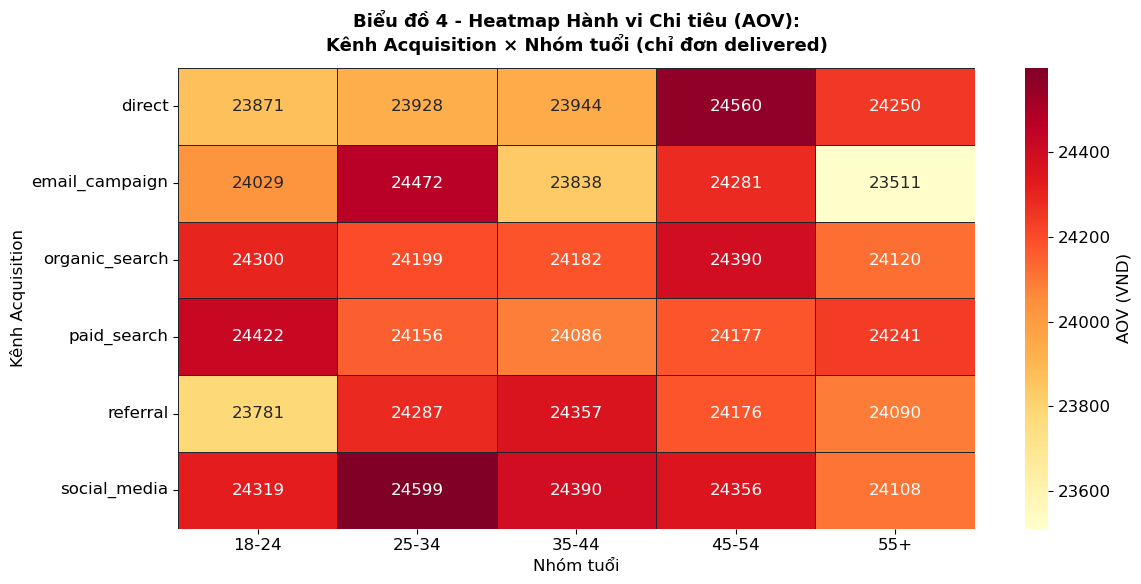

In [274]:
# ── Chart 4: Heatmap AOV – Age Group × Acquisition Channel ──
AGE_ORDER = ['18-24','25-34','35-44','45-54','55+']

df_del = orders[orders['order_status'] == 'delivered'].copy()
df_del = df_del.merge(payments[['order_id','payment_value']], on='order_id', how='left')
df_del = df_del.merge(customers[['customer_id','age_group','acquisition_channel']], on='customer_id', how='left')

pivot4 = df_del.groupby(['acquisition_channel','age_group'])['payment_value'].mean().unstack()
pivot4 = pivot4.reindex(columns=[c for c in AGE_ORDER if c in pivot4.columns])

fig, ax = plt.subplots(figsize=(12, 6))

cmap = sns.color_palette("YlOrRd", as_cmap=True)
sns.heatmap(pivot4, ax=ax, cmap=cmap, annot=True, fmt='.0f',
            linewidths=0.5, linecolor='#21262D',
            cbar_kws={'label': 'AOV (VND)'})

ax.set_xlabel('Nhóm tuổi', fontsize=12)
ax.set_ylabel('Kênh Acquisition', fontsize=12)
plt.title('Biểu đồ 4 - Heatmap Hành vi Chi tiêu (AOV):\nKênh Acquisition × Nhóm tuổi (chỉ đơn delivered)',
          fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
# plt.savefig(BASE_DIR + 'chart4_heatmap_aov.png', dpi=150, bbox_inches='tight')
plt.show()


**Nhận xét**:

Bản đồ nhiệt cho thấy sức mua không được chia đều mà tập trung cục bộ vào những "điểm ngọt" (sweet-spots) nhất định. Mỗi tệp khách hàng lại có một kênh chuyển đổi mang lại giá trị cao riêng biệt:

- Khách hàng trẻ (18-24 tuổi) sẵn sàng chi trả mức AOV cao nhất khi tiếp cận qua kênh email_campaign.

- Khách hàng trung niên (35-44 tuổi) mang lại giá trị tốt nhất khi họ chủ động tìm kiếm (organic_search).

- Đặc biệt, nhóm khách hàng lớn tuổi (45-54 và 55+) cho thấy mức chi tiêu rất lớn qua kênh truyền miệng/giới thiệu (referral).

> Kết luận: Khách hàng đến từ các kênh khác nhau có mức độ nhạy cảm về giá và khả năng chi trả khác nhau. Việc đổ đồng một ngân sách hoặc một thông điệp Marketing cho tất cả các kênh là không hiệu quả.

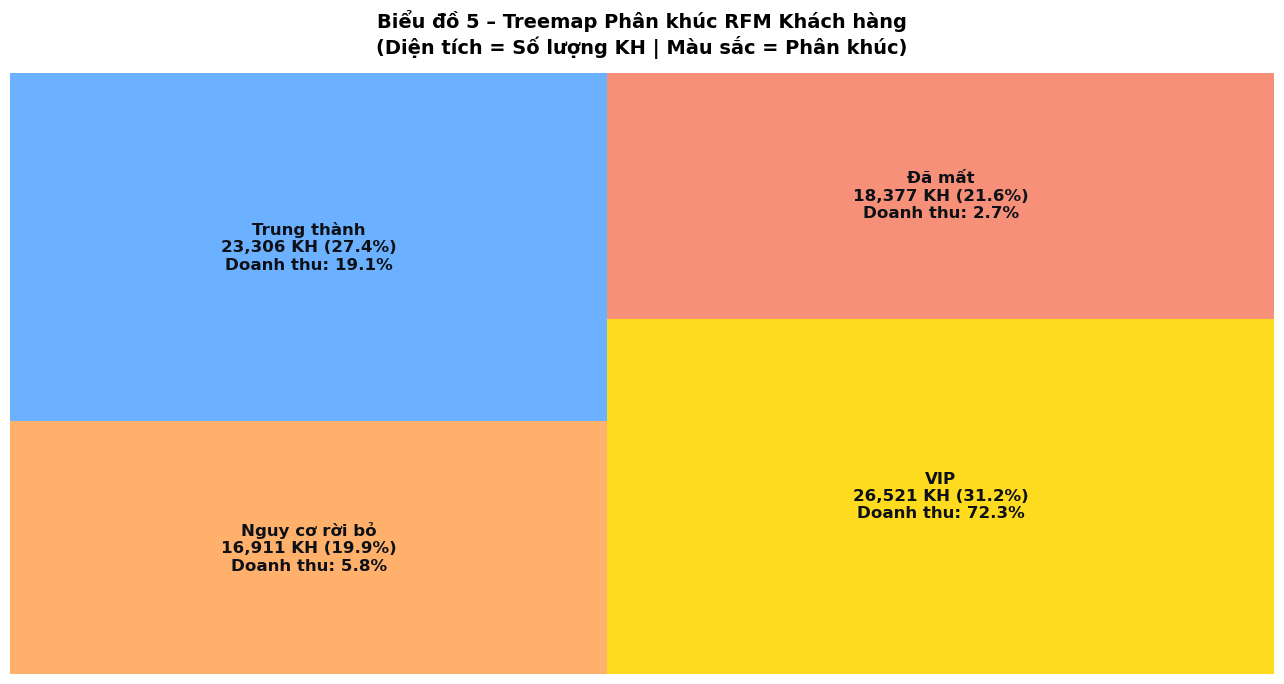

In [302]:
# ── Chart 5: RFM Treemap ──
orders["order_date"] = pd.to_datetime(orders["order_date"])
df_rfm = orders[orders['order_status'] == 'delivered'].copy()
df_rfm = df_rfm.merge(payments[['order_id','payment_value']], on='order_id', how='left')

ref_date = df_rfm['order_date'].max() + pd.Timedelta(days=1)
rfm = df_rfm.groupby('customer_id').agg(
    recency   = ('order_date',    lambda x: (ref_date - x.max()).days),
    frequency = ('order_id',      'count'),
    monetary  = ('payment_value', 'sum')
).reset_index()

# Score 1-4 (recency: lower=better => invert)
rfm['R'] = pd.qcut(rfm['recency'],   4, labels=[4,3,2,1]).astype(int)
rfm['F'] = pd.qcut(rfm['frequency'].rank(method='first'), 4, labels=[1,2,3,4]).astype(int)
rfm['M'] = pd.qcut(rfm['monetary'].rank(method='first'),  4, labels=[1,2,3,4]).astype(int)
rfm['RFM_Score'] = rfm['R'] + rfm['F'] + rfm['M']

def segment(score):
    if score >= 10: return 'VIP'
    if score >= 7:  return 'Trung thành'
    if score >= 5:  return 'Nguy cơ rời bỏ'
    return 'Đã mất'

rfm['Segment'] = rfm['RFM_Score'].apply(segment)

seg_stats = rfm.groupby('Segment').agg(
    customers = ('customer_id', 'count'),
    revenue   = ('monetary',    'sum')
).reset_index()

total_rev  = seg_stats['revenue'].sum()
total_cust = seg_stats['customers'].sum()
seg_stats['rev_pct']  = seg_stats['revenue']  / total_rev  * 100
seg_stats['cust_pct'] = seg_stats['customers'] / total_cust * 100

SEG_COLORS = {
    'VIP':            '#FFD700',
    'Trung thành':    '#58A6FF',
    'Nguy cơ rời bỏ': '#FFA657',
    'Đã mất':         '#F78166',
}

fig, ax = plt.subplots(figsize=(13, 7))
colors = [SEG_COLORS.get(s, '#888') for s in seg_stats['Segment']]
labels = [
    f"{row['Segment']}\n{row['customers']:,} KH ({row['cust_pct']:.1f}%)\nDoanh thu: {row['rev_pct']:.1f}%"
    for _, row in seg_stats.iterrows()
]

squarify.plot(
    sizes=seg_stats['customers'].values,
    label=labels,
    color=colors,
    alpha=0.88,
    text_kwargs={'fontsize': 12, 'fontweight': 'bold', 'color': '#0D1117'},
    ax=ax
)
ax.axis('off')
plt.title('Biểu đồ 5 – Treemap Phân khúc RFM Khách hàng\n(Diện tích = Số lượng KH | Màu sắc = Phân khúc)',
          fontsize=14, fontweight='bold', pad=14)

# Summary annotation
summary_txt = "\n".join([
    f"  {row['Segment']}: {row['cust_pct']:.1f}% KH → {row['rev_pct']:.1f}% Doanh thu"
    for _, row in seg_stats.iterrows()
])
plt.tight_layout()
# plt.savefig(BASE_DIR + 'chart5_rfm_treemap.png', dpi=150, bbox_inches='tight')
plt.show()
# print("✅ Chart 5 saved")


In [298]:
print(summary_txt)

  Nguy cơ rời bỏ: 19.9% KH → 5.8% Doanh thu
  Trung thành: 27.4% KH → 19.1% Doanh thu
  VIP: 31.2% KH → 72.3% Doanh thu
  Đã mất: 21.6% KH → 2.7% Doanh thu


- Chỉ với **31.2%** lượng khách hàng thuộc nhóm **VIP**, nhóm này đã tạo ra sức mạnh gánh vác tới **72.3%** tổng doanh thu của toàn hệ thống. Điều này cho thấy sự tập trung doanh thu cực kỳ lớn vào một tệp khách hàng lõi.
- **Tiềm năng từ nhóm Trung thành:** Nhóm **Trung thành** chiếm **27.4%** số lượng nhưng chỉ mới đóng góp **19.1%** doanh thu. Đây là một tệp "nguồn" rất tiềm năng để Upsell/Cross-sell nhằm chuyển đổi họ lên thành nhóm VIP.
- **Tình trạng "chảy máu" khách hàng:** Có một sự thật đáng báo động là nhóm **Đã mất** và **Nguy cơ rời bỏ** cộng lại chiếm tới **hơn 41.4%** tổng số khách hàng, nhưng chỉ mang lại vỏn vẹn **~8.5%** doanh thu. 
- **Kết luận:** Doanh nghiệp đang tồn tại sự phân hóa rất mạnh về giá trị vòng đời khách hàng. Chiến lược cấp thiết nhất không phải là tiếp tục "đốt tiền" chạy quảng cáo tìm khách mới (bù đắp cho 41% khách hàng đã rời bỏ/ngủ đông), mà là phải dồn nguồn lực chăm sóc và khai thác tối đa nhóm VIP, đồng thời xây dựng kịch bản Retargeting tự động để "đánh thức" nhóm Nguy cơ rời bỏ trước khi họ hoàn toàn trở thành nhóm Đã mất.

### **Phần B: TỔNG HỢP INSIGHT**

**1. Descriptive (Thực trạng - Điều gì đang xảy ra?)**
- Doanh thu và quy mô đơn hàng duy trì đà tăng trưởng tốt. Tuy nhiên, **lợi nhuận thực tế lại biến động mạnh và biên lợi nhuận khá mỏng**.
- Tập khách hàng cốt lõi và đông đảo nhất hiện tại là giới trẻ (GenZ & Millennials từ 18-34 tuổi).

**2. Diagnostic (Chẩn đoán - Tại sao lại xảy ra?)**
- Điểm rò rỉ lợi nhuận lớn nhất nằm ở **Lỗ hổng Vận hành**: Tỷ lệ huỷ (Cancelled) và hoàn đơn (Returned) đặc biệt cao ở nhóm thanh toán **COD**.
- Khách hàng trẻ có xu hướng mua sắm bốc đồng nhưng lại ưu tiên sử dụng COD. Điều này dẫn đến chi phí logistics (cước hoàn hàng) và các chi phí ẩn "ăn mòn" phần lớn lợi nhuận gộp của doanh nghiệp.

**3. Predictive (Dự báo - Hệ quả nếu tiếp diễn?)**
- Nếu tiếp tục mô hình "đốt tiền" chạy quảng cáo để thu hút tệp mass (GenZ) mà không kiểm soát rủi ro từ phương thức thanh toán, doanh nghiệp sẽ rơi vào vòng lặp **"Tăng trưởng ảo"**: Doanh thu (top-line) tăng trưởng liên tục nhưng dòng tiền và lợi nhuận thực tế (bottom-line) ngày càng teo tóp.

**4. Prescriptive (Khuyến nghị - Cần hành động gì?)**
- **Vận hành:** Cần áp dụng rào cản mềm đối với phương thức COD (VD: áp dụng phí vận chuyển cao hơn cho COD, hoặc yêu cầu đặt cọc một phần). Song song đó, khuyến khích thanh toán trước (VNPay/Credit Card) bằng Voucher hoặc Freeship.
- **Tiếp thị & Chăm sóc khách hàng:** Chuyển dịch một phần trọng tâm ngân sách sang tập khách hàng **VIP & Trung thành** (đã được định vị rõ qua phân khúc RFM). Nhóm này có AOV (giá trị đơn hàng) cao và tỷ lệ hoàn trả rất thấp. Cần xây dựng các chương trình Loyalty đặc quyền để tối đa hóa LTV (Customer Lifetime Value).